# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Для збереження інформації з інших клітинок. Пропуски заповнюються шляхом тренування окремого KNeighborsRegressor: рядки без пропусків стають train-множиною, а пропущене значення передбачається на основі решти ознак того ж рядка.
2. Якби ми дивилися тільки на MSE/RMSE під час фінальної оцінки, ми б помилково вирішили, що модель OLS краща. Оцінка на основі комплексу метрик (MAE + MSE + аналіз коефіцієнтів) чітко показує: модель Huber або MAE працює для загальної маси даних набагато точніше (помилка 1.7-1.8 проти 3.1), а високий MSE у них спричинений лише невеликою кількістю аномальних точок, які модель відмовилася підганяти собі на шкоду.
3. MedInc = 0.82, diag_coord = -0,3, bedperroom = 0.19; population = 0.0019
Найбільшу вагу/вплив на ціну дає медіаний дохід жителів. Чим багатший район, тим дорожча нерухомість.
На ціну негативно впливає розташування будинку, чим далі розташований будинок від океану, тим менше будинок коштує. Параметр population майже немає жодної ваги
4.
* Baseline для лінійної регресії - це найпростіша опорна модель, яка завжди передбачає одне й те саме число, середнє значення таргету по тренувальній вибірці `(y_train.mean())`. Вона потрібна для перевірки адекватності: якщо навчена лінійна модель не може побити цей рівень, значить модель марна і не знайшла в ознаках жодного корисного сигналу. Розрахунок: `baseline_pred = np.full_like(y_test, y_train.mean())`

* Baseline для нейромережі — множинна лінійна регресія, яка виступає орієнтиром, завдяки якому можна зрозуміти, що: нейромережа має або невдалі гіперпараметри / недо-пере-навчається, або залежність даних лінійна і складна модель надлишкова. Розрахунок `linear_model = torch.nn.Linear(in_features, 1) + MSELoss`
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції:

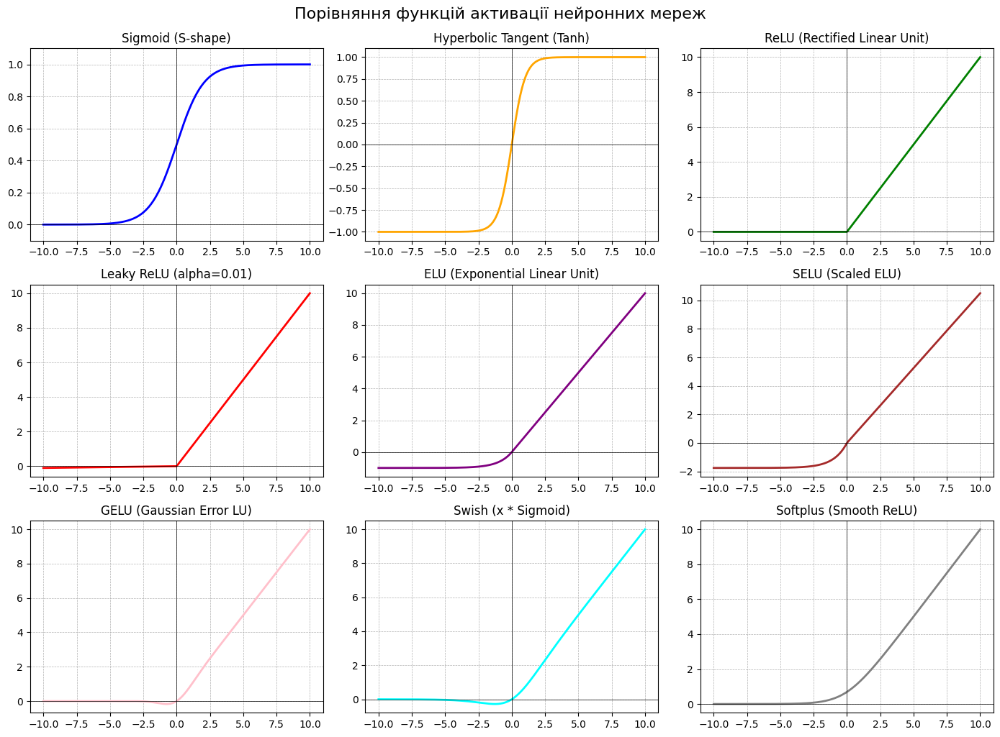

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# геренуємо 1000 випадкових значень
np.random.seed(42)
x = np.linspace(-10, 10, 1000)

# функції активації
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, x)

def leaky_relu(x, alpha=0.01):
    return np.where(x > 0, x, x * alpha)

def elu(x, alpha=1.0):
    return np.where(x > 0, x, alpha * (np.exp(x) - 1))

def selu(x):
    alpha = 1.6732632423543772848170429916717
    scale = 1.0507009873554804934193349852946
    return scale * np.where(x > 0, x, alpha * (np.exp(x) - 1))

def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * np.power(x, 3))))

def swish(x, beta=1.0):
    return x * sigmoid(beta * x)

def softplus(x):
    return np.log(1 + np.exp(x))

# 3. Розраховуємо Y для кожної функції
y_sigmoid = sigmoid(x)
y_tanh = tanh(x)
y_relu = relu(x)
y_leaky_relu = leaky_relu(x)
y_elu = elu(x)
y_selu = selu(x)
y_gelu = gelu(x)
y_swish = swish(x)
y_softplus = softplus(x)

# візуалізація
plt.figure(figsize=(14, 10))

# Створюємо сітку графіків
# plt.subplot(рядок, стовпчик, індекс)

# Sigmoid
plt.subplot(3, 3, 1)
plt.plot(x, y_sigmoid, label='Sigmoid', color='blue', linewidth=2)
plt.title('Sigmoid (S-shape)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.ylim(-0.1, 1.1)

# Tanh
plt.subplot(3, 3, 2)
plt.plot(x, y_tanh, label='Tanh', color='orange', linewidth=2)
plt.title('Hyperbolic Tangent (Tanh)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)
plt.ylim(-1.1, 1.1)

# ReLU
plt.subplot(3, 3, 3)
plt.plot(x, y_relu, label='ReLU', color='green', linewidth=2)
plt.title('ReLU (Rectified Linear Unit)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# Leaky ReLU
plt.subplot(3, 3, 4)
plt.plot(x, y_leaky_relu, label='Leaky ReLU', color='red', linewidth=2)
plt.title('Leaky ReLU (alpha=0.01)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# ELU
plt.subplot(3, 3, 5)
plt.plot(x, y_elu, label='ELU', color='purple', linewidth=2)
plt.title('ELU (Exponential Linear Unit)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# SELU
plt.subplot(3, 3, 6)
plt.plot(x, y_selu, label='SELU', color='brown', linewidth=2)
plt.title('SELU (Scaled ELU)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# GELU
plt.subplot(3, 3, 7)
plt.plot(x, y_gelu, label='GELU', color='pink', linewidth=2)
plt.title('GELU (Gaussian Error LU)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# Swish
plt.subplot(3, 3, 8)
plt.plot(x, y_swish, label='Swish', color='cyan', linewidth=2)
plt.title('Swish (x * Sigmoid)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

# Softplus
plt.subplot(3, 3, 9)
plt.plot(x, y_softplus, label='Softplus', color='gray', linewidth=2)
plt.title('Softplus (Smooth ReLU)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.axhline(0, color='black',linewidth=0.5)
plt.axvline(0, color='black',linewidth=0.5)

plt.tight_layout()
plt.suptitle('Порівняння функцій активації нейронних мереж', fontsize=16, y=1.02)
plt.show()

6.
```python
housing_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

Sequential(
  (0): Linear(in_features=7, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       2625
Кількість параметрів лінійної: 8
```
```python
(0) 7*64+64 = 512
(2) 64*32+32 = 2080
(4) 32+1 = 33
sum = 2625
```

7. Чи оптимально вибрано кількість епох в 3.5?

Цілком оптимально, немає недонавчання/перенавчання, а темп спадання `val_loss` сповільнився до `+-0.0023` одиниць. Проте, оскільки одночасно падали і `train_loss та val_loss`, можна було довчити ще 50-100 епох, але і 200 епох було достатньо



---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [2]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Жеребцов Дмитро Вікторович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#1): King County House Sales


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.



In [3]:
# install and import [datasets](https://huggingface.co/docs/datasets/en/index) library

!pip install -q datasets
from datasets import load_dataset

# Імпортуємо бібліотеки
import sys
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

# Фіксуємо всі джерела випадковості.
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Seed зафіксовано:", SEED)


# Використовуємо графічний прискорювач, якщо доступний.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))




Seed зафіксовано: 42
Використовуємо: cpu


In [4]:
# Монтуємо Google Drive

from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lecture3"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lecture3


In [5]:
housing_dataset = load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")
print(housing_dataset)

data/house_sales_king_county.parquet: reconstructing file:   0%|          |  0.00B /  730kB            

data/house_sales_king_county.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15'],
        num_rows: 21613
    })
})


In [6]:
# convert HuggingFace datasets to pandas DataFrames

housing_df = housing_dataset["train"].to_pandas()

print("\nЗагальний розмір таблиці:", housing_df.shape)


Загальний розмір таблиці: (21613, 21)


In [7]:
from sklearn.model_selection import train_test_split

# Спліт робимо одразу після завантаження — до EDA та обробки пропусків,
# щоб уникнути data leakage: жодна статистика з val/test не повинна впливати
# на рішення під час аналізу та препроцесингу.

# Спочатку відокремлюємо train (60%) від решти (40%),
# потім решту порівну ділимо на val і test (по 20% від усього датасету).
train_df, temp_df = train_test_split(housing_df, test_size=0.4, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"Розмір навчальної вибірки (train): {train_df.shape}")
print(f"Розмір валідаційної вибірки (val): {val_df.shape}")
print(f"Розмір тестової вибірки (test): {test_df.shape}")

Розмір навчальної вибірки (train): (12967, 21)
Розмір валідаційної вибірки (val): (4323, 21)
Розмір тестової вибірки (test): (4323, 21)


In [8]:
# Check the first few rows of the dataset to get an overview
# of the data structure and the features available for analysis.

# відображати нормальні числа, а не 1.28370000e+4
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

train_df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
2679,6791400800,20150413T000000,347500.00,3,1.00,1830,12036,1.00,0,0,...,7,1550,280,1977,0,98042,47.31,-122.04,1810,12036
18912,2425049066,20140616T000000,1920000.00,4,2.50,3070,34412,1.00,0,3,...,9,2070,1000,1950,0,98039,47.64,-122.24,3780,27940
18208,2579500110,20140701T000000,2367000.00,3,2.25,3530,17450,1.00,1,3,...,9,1840,1690,1930,1993,98040,47.54,-122.21,3530,17310
17819,2420069268,20140821T000000,184900.00,2,1.00,1230,5000,1.00,0,0,...,6,1230,0,1911,0,98022,47.21,-121.99,1230,5413
9459,721049096,20140527T000000,569950.00,5,4.50,4850,40902,2.00,0,0,...,10,4850,0,2001,0,98023,47.32,-122.34,1640,13503


In [9]:
# Check the data types and non-null counts of each column to understand the dataset's structure and identify any missing values.

train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12967 entries, 2679 to 15795
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             12967 non-null  int64  
 1   date           12967 non-null  object 
 2   price          12967 non-null  float64
 3   bedrooms       12967 non-null  int64  
 4   bathrooms      12967 non-null  float64
 5   sqft_living    12967 non-null  int64  
 6   sqft_lot       12967 non-null  int64  
 7   floors         12967 non-null  float64
 8   waterfront     12967 non-null  int64  
 9   view           12967 non-null  int64  
 10  condition      12967 non-null  int64  
 11  grade          12967 non-null  int64  
 12  sqft_above     12967 non-null  int64  
 13  sqft_basement  12967 non-null  int64  
 14  yr_built       12967 non-null  int64  
 15  yr_renovated   12967 non-null  int64  
 16  zipcode        12967 non-null  int64  
 17  lat            12967 non-null  float64
 18  long    

In [10]:
# Get a summary of the dataset's statistics.

train_df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00,12967.00
mean,4577285109.39,537141.53,3.36,2.11,2073.85,14974.18,1.50,0.01,0.23,3.41,7.65,1784.38,289.47,1971.13,84.64,98078.37,47.56,-122.21,1980.76,12704.34
std,2865659300.69,353491.82,0.90,0.76,906.09,39596.37,0.54,0.08,0.76,0.65,1.17,821.54,440.52,29.41,402.19,53.40,0.14,0.14,681.47,26740.10
min,1000102.00,75000.00,0.00,0.00,290.00,520.00,1.00,0.00,0.00,1.00,1.00,290.00,0.00,1900.00,0.00,98001.00,47.16,-122.52,399.00,651.00
25%,2130555455.00,321000.00,3.00,1.75,1420.00,5000.00,1.00,0.00,0.00,3.00,7.00,1200.00,0.00,1951.00,0.00,98033.00,47.47,-122.33,1480.00,5080.00
50%,3904930730.00,450000.00,3.00,2.25,1910.00,7565.00,1.50,0.00,0.00,3.00,7.00,1560.00,0.00,1975.00,0.00,98070.00,47.57,-122.23,1830.00,7600.00
75%,7300000600.00,640000.00,4.00,2.50,2550.00,10660.00,2.00,0.00,0.00,4.00,8.00,2190.00,560.00,1997.00,0.00,98118.00,47.68,-122.12,2360.00,10051.00
max,9900000190.00,7700000.00,10.00,8.00,12050.00,1164794.00,3.50,1.00,4.00,5.00,13.00,8570.00,4820.00,2015.00,2015.00,98199.00,47.78,-121.32,6210.00,871200.00


In [11]:
train_df[housing_df.isnull().any(axis=1)]

/tmp/ipykernel_1738/1329758926.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  train_df[housing_df.isnull().any(axis=1)]


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


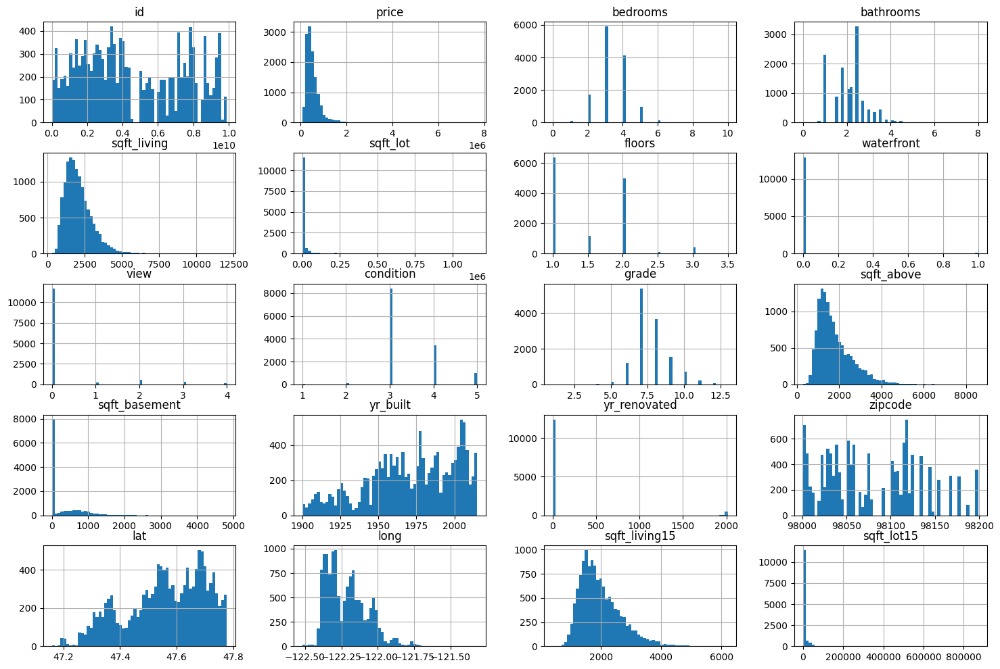

In [12]:
train_df.hist(bins=60, figsize=(18, 12))
plt.show()

# Підготовка даних
1. Розкид масштабів

`price` вимірюється сотнями тисяч, `sqft_lot` - мільйонами, а `floors` та `bathrooms` одиницями

2. Outliers
* Максимум ціни — `7.7 млн` при медіані в `450 тис`
* Є будинки з `0` спалень або `0` ванних кімнат
* Хтось має ділянку понад `1 млн кв. футів`

3. Sparse/Binary
* `waterfront`: середнє `0.0068`, тобто лише незначна частина будинків мають вихід до води
* `yr_renovated`: `75%` значень дорівнюють `0.0`

In [13]:

from scipy.stats import skew

# скільки рядків мають рівно максимальне значення
max_counts = []
for col in train_df.columns:
    if col == "id":
        continue
    max_val = train_df[col].max()
    count_at_max = (train_df[col] == max_val).sum()
    share = (count_at_max / len(train_df)) * 100
    max_counts.append(
        {
            "feature": col,
            "max_value": max_val,
            "count_at_max": count_at_max,
            "share_%": round(share, 4),
        }
    )

max_df = pd.DataFrame(max_counts).sort_values("count_at_max", ascending=False)
print("--- 1. Кількість значень на максимумі ---")
print(max_df.to_string(index=False))

# Skewness для всіх числових полів
# Skewness ≈ 0  -> симетричний розподіл
# Skewness > 1  -> довгий правий хвіст
# Skewness < -1 -> довгий лівий хвіст

skew_list = []
numeric_cols = train_df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
    if col == "id":
        continue
    s = train_df[col].skew()
    skew_list.append({"feature": col, "skewness": round(s, 2)})

skew_df = pd.DataFrame(skew_list).sort_values(
    by="skewness", key=abs, ascending=False
)
print("\n--- 2. Скошеність ознак (Skewness) ---")
print(skew_df.to_string(index=False))

# Видалення явних аномалій (Outliers)
initial_len = len(train_df)

# Фільтри на основі попереднього аналізу df.describe():
# - sqft_lot > 1_000_000 (аномально гігантські ділянки)
# - bedrooms == 0 або bathrooms == 0 (будинки без спалень чи санвузла)
# - bedrooms >= 10 (якщо це одиничний викид на зразок будинку з 33 спальнями)
clean_condition = (
    (train_df["sqft_lot"] <= 800000)
    & (train_df["bedrooms"] > 0)
    & (train_df["bathrooms"] > 0)
    & (train_df["bedrooms"] < 10)
)

train_df_clean = train_df[clean_condition].copy()
removed_rows = initial_len - len(train_df_clean)

print("\n--- 3. Результат очищення від аномалій ---")
print(f"Початкова кількість рядків: {initial_len}")
print(
    f"Видалено аномальних рядків: {removed_rows} ({removed_rows / initial_len * 100:.2f}%)"
)
print(f"Залишилося рядків: {len(train_df_clean)}")

--- 1. Кількість значень на максимумі ---
      feature       max_value  count_at_max  share_%
    condition               5          1022     7.88
      zipcode           98199           188     1.45
         view               4           179     1.38
   waterfront               1            89     0.69
     yr_built            2015            24     0.19
 yr_renovated            2015             7     0.05
        grade              13             6     0.05
       floors            3.50             4     0.03
          lat           47.78             2     0.02
     bedrooms              10             2     0.02
         date 20150515T000000             1     0.01
        price      7700000.00             1     0.01
    bathrooms            8.00             1     0.01
   sqft_above            8570             1     0.01
     sqft_lot         1164794             1     0.01
  sqft_living           12050             1     0.01
sqft_basement            4820             1     0.01
    

In [14]:
train_df_clean.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00,12950.00
mean,4578591443.69,537034.02,3.36,2.11,2073.42,14513.26,1.50,0.01,0.23,3.41,7.65,1784.01,289.41,1971.13,84.75,98078.43,47.56,-122.22,1980.57,12596.81
std,2865717349.28,353230.34,0.89,0.76,904.34,33315.47,0.54,0.08,0.76,0.65,1.17,820.28,440.14,29.40,402.45,53.41,0.14,0.14,681.14,25422.45
min,1000102.00,80000.00,1.00,0.50,380.00,520.00,1.00,0.00,0.00,1.00,4.00,380.00,0.00,1900.00,0.00,98001.00,47.16,-122.52,399.00,651.00
25%,2130482752.50,321145.25,3.00,1.75,1425.50,5000.00,1.00,0.00,0.00,3.00,7.00,1200.00,0.00,1951.00,0.00,98033.00,47.47,-122.33,1480.00,5074.50
50%,3904945175.00,450000.00,3.00,2.25,1910.00,7561.00,1.50,0.00,0.00,3.00,7.00,1560.00,0.00,1975.00,0.00,98070.00,47.57,-122.23,1830.00,7596.50
75%,7300350117.50,639972.00,4.00,2.50,2550.00,10647.50,2.00,0.00,0.00,4.00,8.00,2190.00,560.00,1997.00,0.00,98118.00,47.68,-122.13,2360.00,10045.25
max,9900000190.00,7700000.00,9.00,8.00,12050.00,715690.00,3.50,1.00,4.00,5.00,13.00,8570.00,4820.00,2015.00,2015.00,98199.00,47.78,-121.32,6210.00,438213.00


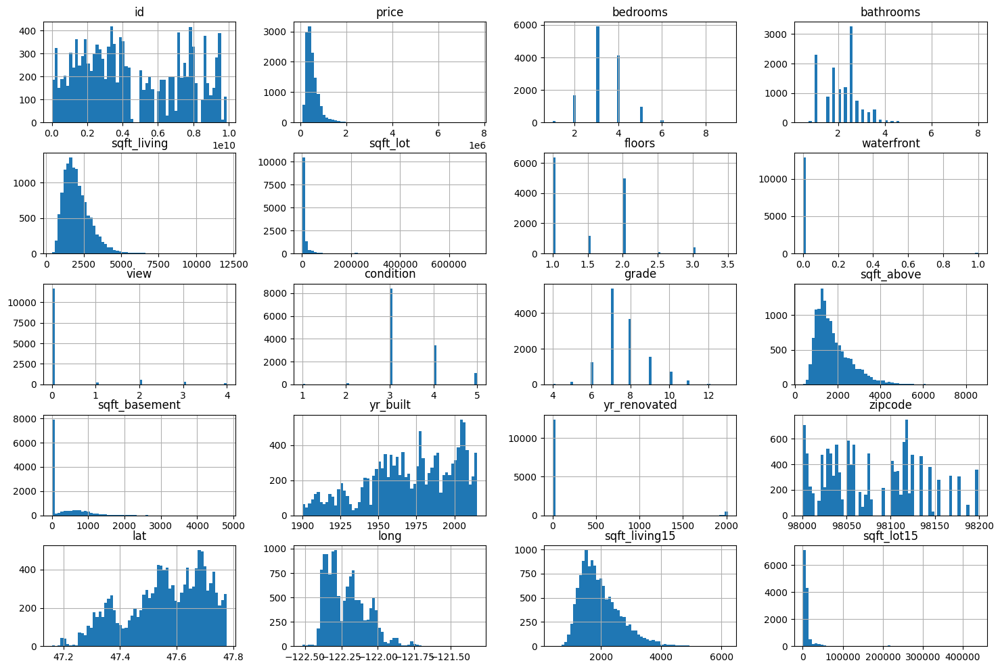

In [15]:

train_df_clean.hist(bins=60, figsize=(18, 12))
plt.show()

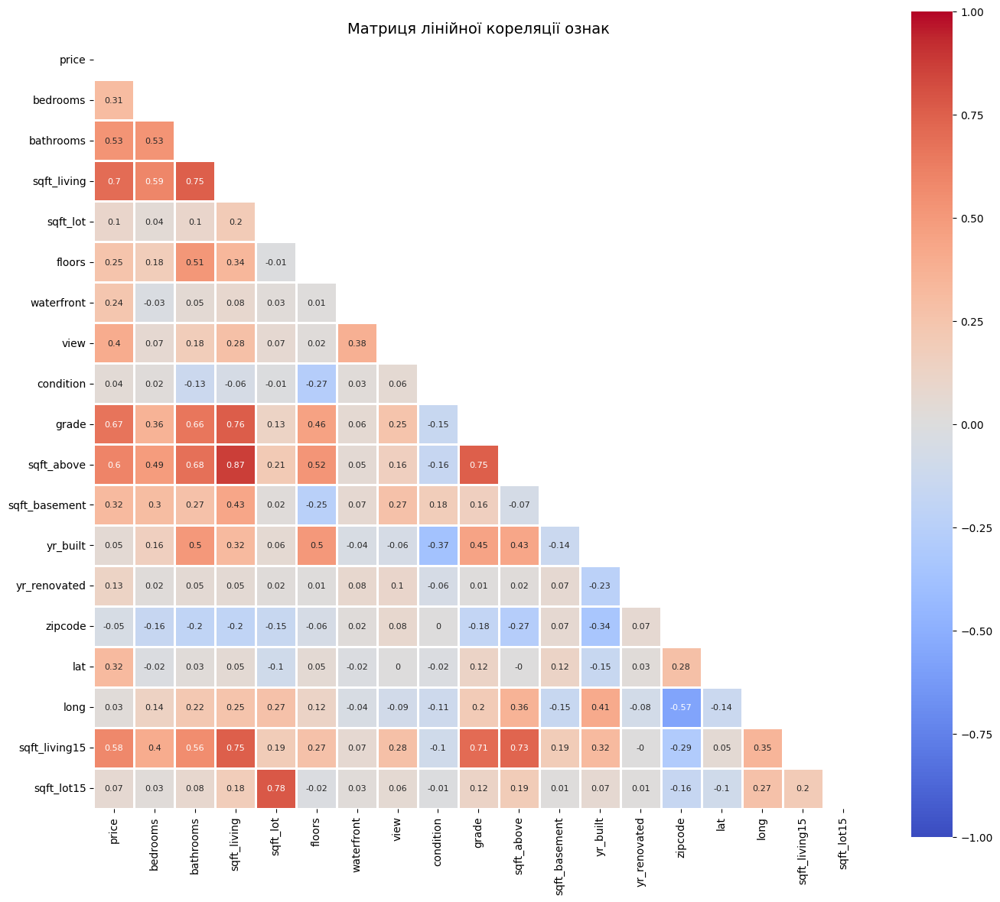

In [16]:
import seaborn as sns

def corr_mat(df):
    # Викидаємо id та рахуємо кореляцію тільки для числових колонок
    cols_to_ignore = [c for c in ["id", "date"] if c in df.columns]
    df_numeric = df.drop(columns=cols_to_ignore)

    # numeric_only=True гарантує, що рядкові типи будуть проігноровані
    corr = df_numeric.corr(numeric_only=True).round(2)
    f, ax = plt.subplots(figsize=(14, 12))

    mask = np.zeros_like(corr, dtype=bool)
    mask[np.triu_indices_from(mask)] = True

    sns.heatmap(
        corr,
        mask=mask,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="coolwarm",
        square=True,
        lw=1,
        annot=True,
        annot_kws={"size": 8},
        cbar=True,
    )

    plt.title("Матриця лінійної кореляції ознак", fontsize=14)
    plt.tight_layout()
    plt.show()

corr_mat(train_df_clean)

# Кореляції
* `sqft_living — sqft_above (0.87)`: пряме дублювання площі, оскільки житлова площа майже повністю складається з надземної частини
* `sqft_living — sqft_living15 (0.78)`: розмір будинку практично відповідає типовому розміру будинків у найближчих сусідів
* `sqft_living — grade (0.76)`: більші будинки майже завжди будуються за вищим класом матеріалів та дизайну
* `sqft_lot — sqft_lot15 (0.78)`: площа земельної ділянки однорідна в межах одного району
* `bathrooms — sqft_living (0.75)`: кількість санвузлів безпосередньо пропорційна загальній площі будинку
* `condition — yr_built (-0.37)`: старіші будинки мають гірший фізичний стан, але сам по собі condition майже не корелює з price (0.04)

In [17]:

def transform_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # нові ознаки
    # бінарний прапорець наявності підвалу
    df["has_basement"] = (df["sqft_basement"] > 0).astype(int)

    # порівняння з сусідами, відносні коефіцієнти
    df["living_vs_neighbors"] = df["sqft_living"] / (df["sqft_living15"] + 1)
    df["lot_vs_neighbors"] = df["sqft_lot"] / (df["sqft_lot15"] + 1)

    # відносні метрики по кімнатам
    safe_bedrooms = df["bedrooms"].replace(0, 1)
    df["sqft_per_bedroom"] = df["sqft_living"] / safe_bedrooms
    df["bath_per_bed"] = df["bathrooms"] / safe_bedrooms

    df["is_renovated"] = (df["yr_renovated"] > 0).astype(int)
    df["effective_yr"] = np.where(
        df["yr_renovated"] > 0, df["yr_renovated"], df["yr_built"]
    )

    # відстань до ділового центру Сіетла
    SEATTLE_LAT = 47.6062
    SEATTLE_LONG = -122.3321
    df["dist_to_seattle"] = np.sqrt(
      (df["lat"] - SEATTLE_LAT) ** 2 + (df["long"] - SEATTLE_LONG) ** 2
    )

    # видалення надлишкових колонок, що створюють колінеарність
    cols_to_drop = [
        "sqft_above",
        "sqft_basement",
        "sqft_living15",
        "sqft_lot15",
        "yr_renovated",
        "long",
        "lat",
    ]
    df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

    return df

train_df_clean = transform_features(train_df_clean)

print("Розмірність після трансформації ознак:", train_df_clean.shape)
print("Залишені ознаки:", train_df_clean.columns.tolist())
#print(train_df_clean[train_df_clean.isnull().any(axis=1)])

Розмірність після трансформації ознак: (12950, 22)
Залишені ознаки: ['id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'zipcode', 'has_basement', 'living_vs_neighbors', 'lot_vs_neighbors', 'sqft_per_bedroom', 'bath_per_bed', 'is_renovated', 'effective_yr', 'dist_to_seattle']


In [18]:
val_df_clean = transform_features(val_df)
test_df_clean = transform_features(test_df)

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.



In [19]:
from sklearn.preprocessing import StandardScaler

# стандартизація ознак
# викидаємо таргет та службові поля
ignore_cols = ["price", "id", "date"]
feature_cols = [c for c in train_df_clean.columns if c not in ignore_cols]

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df_clean[feature_cols])
X_val = scaler.transform(val_df_clean[feature_cols])
X_test = scaler.transform(test_df_clean[feature_cols])

PRICE_SCALE = 100_000.0

y_train = train_df_clean["price"].values / PRICE_SCALE
y_val = val_df_clean["price"].values / PRICE_SCALE
y_test = test_df_clean["price"].values / PRICE_SCALE

print("Кількість ознак:", len(feature_cols))
print("Форма X_train:", X_train.shape)
print("Форма X_val:", X_val.shape)
print("Форма X_test:", X_test.shape)

Кількість ознак: 19
Форма X_train: (12950, 19)
Форма X_val: (4323, 19)
Форма X_test: (4323, 19)


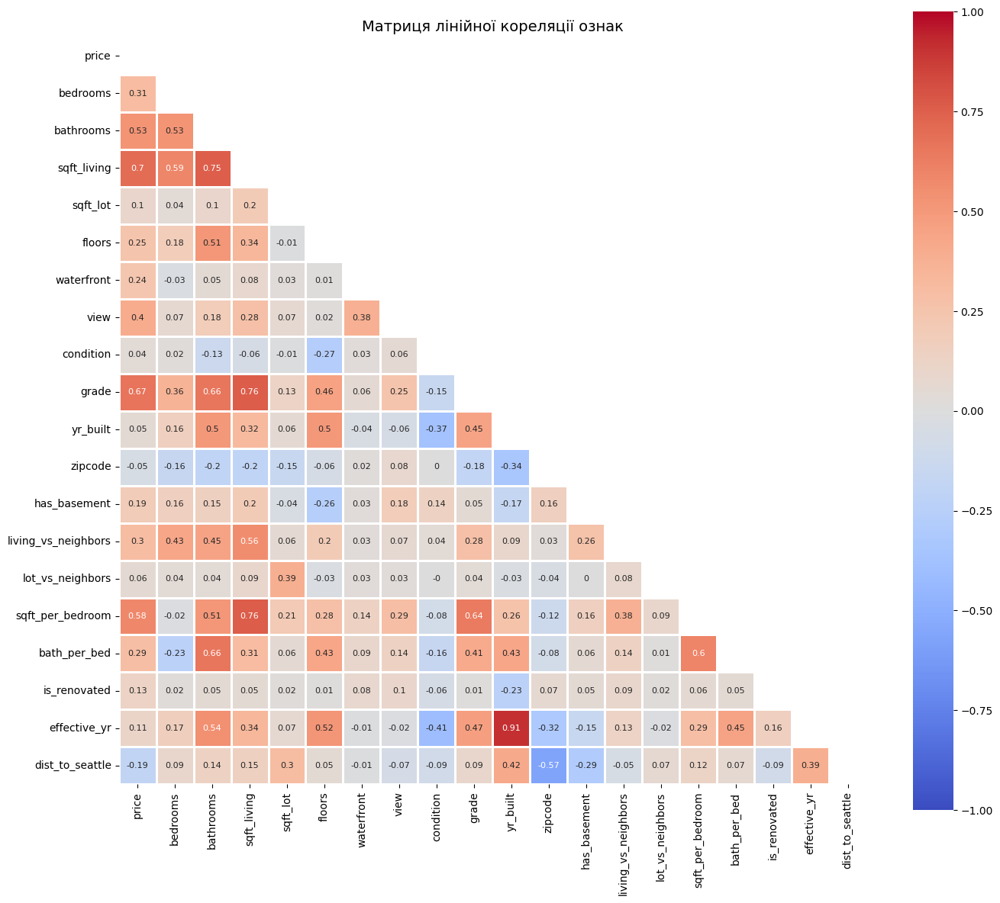

In [20]:
corr_mat(train_df_clean)

In [21]:
# Конвертуємо в тензори PyTorch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

print("x_train_t shape:", x_train_t.shape, "device:", x_train_t.device)
print("y_train_t shape:", y_train_t.shape, "device:", y_train_t.device)

x_train_t shape: torch.Size([12950, 19]) device: cpu
y_train_t shape: torch.Size([12950, 1]) device: cpu


In [22]:
!pip install --upgrade sympy

In [23]:

from torch.utils.tensorboard import SummaryWriter

N_EPOCHS = 40

n_features = X_train.shape[1]

linear_model = torch.nn.Linear(
    in_features=n_features,
    out_features=1
).to(device)

optimizer = torch.optim.SGD(
    linear_model.parameters(),
    lr=0.1
)

loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(
    log_dir=os.path.join(RUNS_DIR, "linear_regression")
)

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS):
    linear_model.train()

    optimizer.zero_grad()

    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    linear_model.eval()

    with torch.no_grad():
        val_loss = loss_fn(
            linear_model(x_val_t),
            y_val_t
        ).item()

    val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 3 == 0 or epoch == N_EPOCHS - 1:
        rmse_train = loss.item() ** 0.5 * PRICE_SCALE
        rmse_val = val_loss ** 0.5 * PRICE_SCALE

        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}  "
            f"val_RMSE=${rmse_val:,.0f}"
        )

writer.close()

epoch    0  train_loss=38.4961  val_loss=24.3260  val_RMSE=$493,214
epoch    3  train_loss=12.1014  val_loss=9.5550  val_RMSE=$309,111
epoch    6  train_loss=6.1320  val_loss=5.6856  val_RMSE=$238,444
epoch    9  train_loss=4.4982  val_loss=4.6181  val_RMSE=$214,899
epoch   12  train_loss=4.0282  val_loss=4.3080  val_RMSE=$207,557
epoch   15  train_loss=3.8806  val_loss=4.2083  val_RMSE=$205,141
epoch   18  train_loss=3.8262  val_loss=4.1696  val_RMSE=$204,195
epoch   21  train_loss=3.8009  val_loss=4.1497  val_RMSE=$203,709
epoch   24  train_loss=3.7858  val_loss=4.1365  val_RMSE=$203,383
epoch   27  train_loss=3.7749  val_loss=4.1259  val_RMSE=$203,123
epoch   30  train_loss=3.7659  val_loss=4.1166  val_RMSE=$202,894
epoch   33  train_loss=3.7581  val_loss=4.1081  val_RMSE=$202,685
epoch   36  train_loss=3.7511  val_loss=4.1002  val_RMSE=$202,490
epoch   39  train_loss=3.7445  val_loss=4.0928  val_RMSE=$202,306


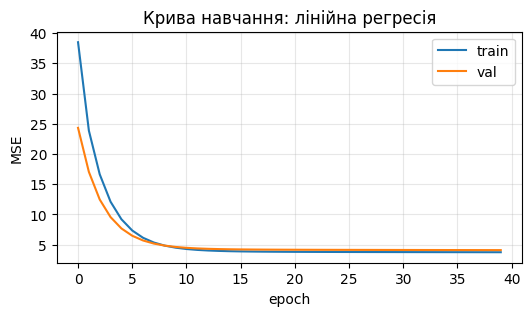

In [24]:
# крива навчання
plt.figure(figsize=(6, 3))
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: лінійна регресія")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [108]:
# baseline порівняння
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear_model.eval()
with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())


def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:45s}  MSE={mse:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")


report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")

Бейзлайн                                       MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія                                  MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877


Лінійна регресія суттєво перевершила baseline і пояснює близько 69% варіації цільової змінної, але помилка все одно велика, що вказує на доцільність використання нелінійної нейромережі.

In [26]:
weights = linear_model.weight.detach().cpu().numpy().flatten()
weight_df = pd.DataFrame({"feature": feature_cols, "weight": weights})
weight_df["abs_weight"] = weight_df["weight"].abs()
weight_df = weight_df.sort_values("abs_weight", ascending=False).drop(columns="abs_weight")

print(weight_df.to_string(index=False))

            feature  weight
              grade    1.23
        sqft_living    1.09
    dist_to_seattle   -1.04
   sqft_per_bedroom    0.54
          bathrooms    0.51
         waterfront    0.44
           yr_built   -0.42
            zipcode   -0.38
               view    0.35
living_vs_neighbors   -0.33
       bath_per_bed   -0.20
       effective_yr   -0.19
       is_renovated    0.17
          condition    0.14
       has_basement   -0.13
           sqft_lot    0.09
             floors    0.04
           bedrooms    0.01
   lot_vs_neighbors    0.00


Найбільший внесок у прогнозування вартості житла мають клас будинку `grade`, житлова площа `sqft_living` та відстань до Сіетла `dist_to_seattle`.

Зі збільшенням класу та площі прогнозована ціна зростає, тоді як збільшення відстані від економічного центру пов'язане зі зниженням вартості.

Створена ознака `sqft_per_bedroom` також виявилася інформативною та частково перебрала на себе інформацію, яку містила кількість спалень `bedrooms`.

Водночас деякі створені ознаки, зокрема `lot_vs_neighbors` та `has_basement`, мають невеликий додатковий внесок у лінійну модель.

Коефіцієнт `zipcode` слід оцінювати обережно, оскільки поштовий індекс фактично є категоріальною, а не неперервною числовою ознакою

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.



In [42]:
# Два приховані шари з ReLU: n_features → 64 → 32 → 1. Вхід — ті самі стандартизовані ознаки,
# що й у лінійній регресії (x_train_t), жодного додаткового feature engineering

housing_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(housing_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in housing_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       3393
Кількість параметрів лінійної: 20


In [43]:
# тренуємо модель
# та сама логіка циклу навчання, що й для лінійної регресії — тільки модель і оптимізатор інші.
# І так само логуємо в TensorBoard, в окрему підпапку RUNS_DIR

N_EPOCHS = 500

optimizer = torch.optim.Adam(housing_nn.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "neural_network"))

nn_train_losses, nn_val_losses = [], []

for epoch in range(N_EPOCHS):
    housing_nn.train()
    optimizer.zero_grad()
    y_pred = housing_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    nn_train_losses.append(loss.item())

    housing_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(housing_nn(x_val_t), y_val_t).item()
    nn_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:4d}  train_loss={loss.item():.4f}  val_loss={val_loss:.4f}")

writer.close()

epoch    0  train_loss=39.6530  val_loss=36.5719
epoch   10  train_loss=10.9062  val_loss=12.7733
epoch   20  train_loss=5.4144  val_loss=5.3972
epoch   30  train_loss=3.9386  val_loss=4.2227
epoch   40  train_loss=3.2480  val_loss=3.5795
epoch   50  train_loss=2.9481  val_loss=3.3179
epoch   60  train_loss=2.8393  val_loss=3.2462
epoch   70  train_loss=2.7351  val_loss=3.1389
epoch   80  train_loss=2.6598  val_loss=3.0678
epoch   90  train_loss=2.5992  val_loss=3.0205
epoch  100  train_loss=2.5423  val_loss=2.9715
epoch  110  train_loss=2.4911  val_loss=2.9234
epoch  120  train_loss=2.4428  val_loss=2.8796
epoch  130  train_loss=2.3904  val_loss=2.8398
epoch  140  train_loss=2.3447  val_loss=2.8017
epoch  150  train_loss=2.3028  val_loss=2.7686
epoch  160  train_loss=2.2640  val_loss=2.7399
epoch  170  train_loss=2.2262  val_loss=2.7139
epoch  180  train_loss=2.1893  val_loss=2.6916
epoch  190  train_loss=2.1531  val_loss=2.6681
epoch  200  train_loss=2.1168  val_loss=2.6291
epoch  21

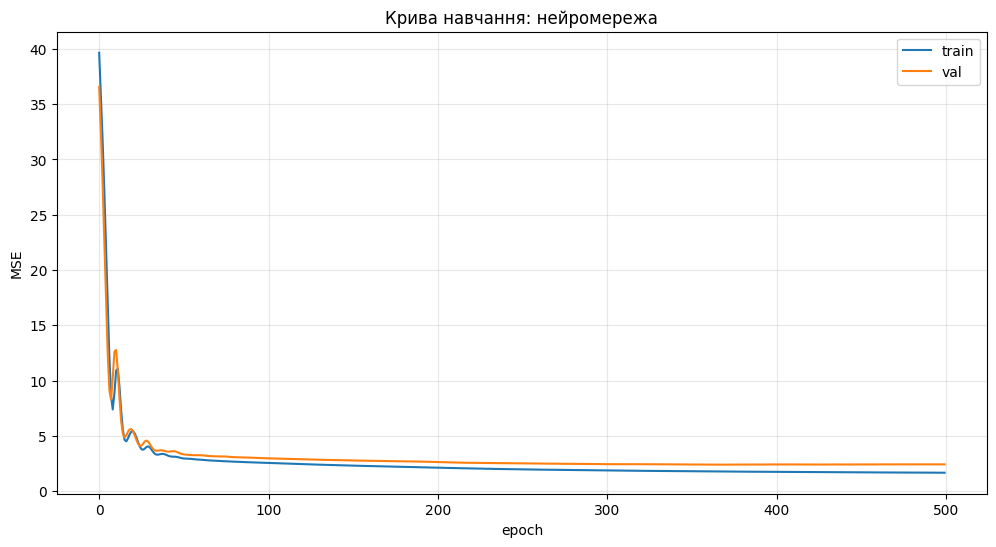

In [44]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(nn_train_losses, label="train")
plt.plot(nn_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [45]:
# Метрики
housing_nn.eval()
with torch.no_grad():
    y_test_pred_nn = housing_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")

Бейзлайн        MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія   MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа     MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440


Типова помилка в ціні в нейромережі менша від лін. регресії на `~70 000$`, середня абсолютна похибка менша на `~30 000$`, і нейромережа пояснює `85%` варіативності цін, що на `17%` більше ніж лін. регресія

In [69]:
# Архітектура 2

# Три приховані шари з ReLU: n_features → 128 → 64 → 32 → 1
# Що потенційно дасть можливість мережі вловлювати більше закономірностей

deep_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.ReLU(),
    torch.nn.Linear(128, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(deep_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in deep_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): ReLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       12929
Кількість параметрів лінійної: 20


In [70]:
N_EPOCHS = 500

optimizer = torch.optim.Adam(deep_nn.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "deep_neural_network"))

deep_train_losses, deep_val_losses = [], []

for epoch in range(N_EPOCHS):
    deep_nn.train()
    optimizer.zero_grad()
    y_pred = deep_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    deep_train_losses.append(loss.item())

    deep_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(deep_nn(x_val_t), y_val_t).item()
    deep_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:4d}  train_loss={loss.item():.4f}  val_loss={val_loss:.4f}")

writer.close()

epoch    0  train_loss=42.8698  val_loss=39.4729
epoch   10  train_loss=7.0096  val_loss=8.1155
epoch   20  train_loss=3.7513  val_loss=3.8730
epoch   30  train_loss=3.6792  val_loss=4.0789
epoch   40  train_loss=3.0341  val_loss=3.5195
epoch   50  train_loss=2.8199  val_loss=3.2142
epoch   60  train_loss=2.6978  val_loss=3.1111
epoch   70  train_loss=2.5904  val_loss=2.9941
epoch   80  train_loss=2.4962  val_loss=2.9091
epoch   90  train_loss=2.4053  val_loss=2.8248
epoch  100  train_loss=2.3054  val_loss=2.7247
epoch  110  train_loss=2.1991  val_loss=2.6295
epoch  120  train_loss=2.0942  val_loss=2.5398
epoch  130  train_loss=2.0144  val_loss=2.4897
epoch  140  train_loss=1.9554  val_loss=2.4526
epoch  150  train_loss=1.9066  val_loss=2.4281
epoch  160  train_loss=1.8614  val_loss=2.4106
epoch  170  train_loss=1.8221  val_loss=2.3912
epoch  180  train_loss=1.7982  val_loss=2.3822
epoch  190  train_loss=1.7538  val_loss=2.3532
epoch  200  train_loss=1.7222  val_loss=2.3464
epoch  210 

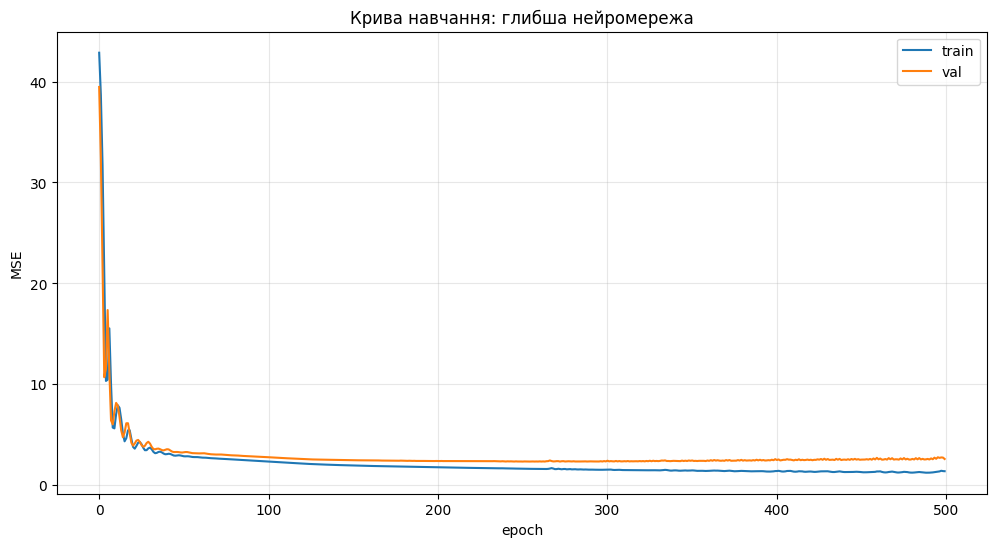

In [80]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(deep_train_losses, label="train")
plt.plot(deep_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: глибша нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [73]:
# Метрики
deep_nn.eval()

with torch.no_grad():
    y_test_pred_deep_nn = deep_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")

Бейзлайн        MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія   MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа     MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа  MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450


Збільшення глибини мережі з двох до трьох прихованих шарів не покращило результат при однакових параметрах навчання. Більш складна модель продемонструвала мізерне покращення

In [75]:
# Архітектура 3

# Три приховані шари з SiLu: n_features → 128 → 64 → 32 → 1
# Що потенційно дасть можливість мережі вловлювати більше закономірностей
# А з SiLu протестуємо більш плавну функцію активації для такої задачі

deep_silu_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.SiLU(),
    torch.nn.Linear(128, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 32),
    torch.nn.SiLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(deep_silu_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in deep_silu_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=128, bias=True)
  (1): SiLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): SiLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): SiLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       12929
Кількість параметрів лінійної: 20


In [76]:
N_EPOCHS = 500

optimizer = torch.optim.Adam(deep_silu_nn.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "deep_silu_neural_network"))

deep_silu_train_losses, deep_silu_val_losses = [], []

for epoch in range(N_EPOCHS):
    deep_silu_nn.train()
    optimizer.zero_grad()
    y_pred = deep_silu_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    deep_silu_train_losses.append(loss.item())

    deep_silu_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(deep_silu_nn(x_val_t), y_val_t).item()
    deep_silu_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:4d}  train_loss={loss.item():.4f}  val_loss={val_loss:.4f}")

writer.close()

epoch    0  train_loss=40.9649  val_loss=38.9288
epoch   10  train_loss=6.2259  val_loss=6.6126
epoch   20  train_loss=3.6977  val_loss=4.0169
epoch   30  train_loss=2.8384  val_loss=3.2658
epoch   40  train_loss=2.5898  val_loss=3.0046
epoch   50  train_loss=2.4313  val_loss=2.8088
epoch   60  train_loss=2.3296  val_loss=2.7090
epoch   70  train_loss=2.2338  val_loss=2.6293
epoch   80  train_loss=2.1635  val_loss=2.5620
epoch   90  train_loss=2.1073  val_loss=2.5067
epoch  100  train_loss=2.0591  val_loss=2.4702
epoch  110  train_loss=2.0154  val_loss=2.4411
epoch  120  train_loss=1.9739  val_loss=2.4078
epoch  130  train_loss=1.9326  val_loss=2.3789
epoch  140  train_loss=1.8917  val_loss=2.3516
epoch  150  train_loss=1.8515  val_loss=2.3297
epoch  160  train_loss=1.8121  val_loss=2.3106
epoch  170  train_loss=1.7755  val_loss=2.2929
epoch  180  train_loss=1.7415  val_loss=2.2803
epoch  190  train_loss=1.7096  val_loss=2.2728
epoch  200  train_loss=1.6845  val_loss=2.2769
epoch  210 

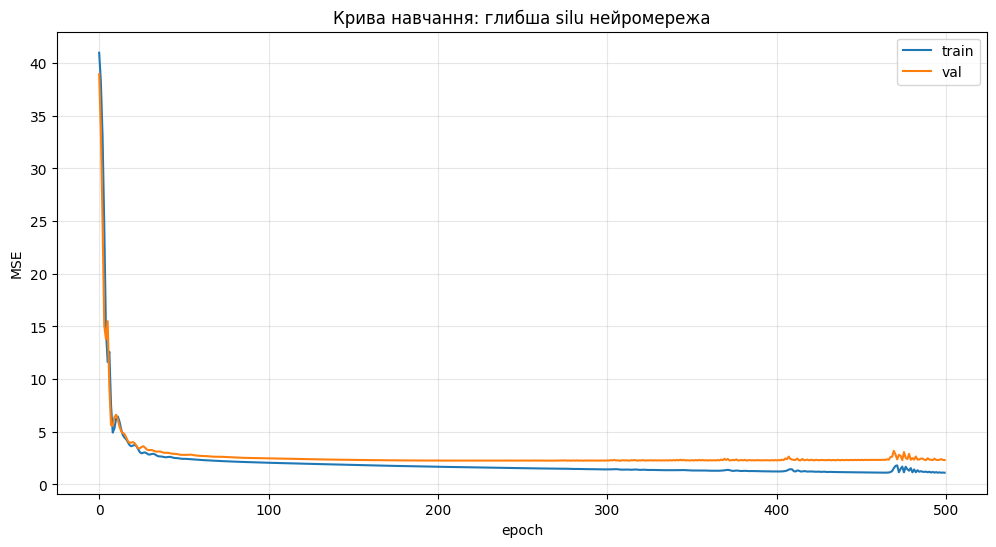

In [79]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(deep_silu_train_losses, label="train")
plt.plot(deep_silu_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: глибша silu нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [81]:
# Метрики
deep_silu_nn.eval()

with torch.no_grad():
    y_test_pred_deep_silu_nn = deep_silu_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")
report(y_test, y_test_pred_deep_silu_nn, "Глибша silu нейромережа")

Бейзлайн        MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія   MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа     MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа  MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450
Глибша silu нейромережа  MSE=2.4382  RMSE=1.5615  MAE=0.9698  R2=0.8549


Порівняння трьох архітектур показало, що збільшення кількості прихованих шарів прискорило навчання моделі, однак саме по собі дало лише незначне покращення якості. Найкращий результат показала глибока мережа з функцією активації SiLU. Вона швидше зменшувала validation loss та досягла найменшого значення близько `2.26`, тоді як глибока мережа з ReLU — близько `2.30`, а базова — близько `2.40`. Після приблизно `200–270` епох у глибоких моделях спостерігається плато validation loss при подальшому зменшенні train loss, що свідчить про початок перенавчання.

epoch 100:
* Base ReLU      val ≈ 2.9715
* Deep ReLU      val ≈ 2.7247
* Deep SiLU      val ≈ 2.4702

epoch 150:
* Base ReLU      2.7686
* Deep ReLU      2.4281
* Deep SiLU      2.3297

epoch 200:
* Base ReLU      2.6291
* Deep ReLU      2.3464
* Deep SiLU      2.2769

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.



In [85]:
# 1) Deep SiLU Slow
# Три приховані шари з SiLu: n_features → 128 → 64 → 32 → 1

deep_silu_slow_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.SiLU(),
    torch.nn.Linear(128, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 32),
    torch.nn.SiLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(deep_silu_slow_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in deep_silu_slow_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=128, bias=True)
  (1): SiLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): SiLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): SiLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       12929
Кількість параметрів лінійної: 20


In [86]:
N_EPOCHS = 500
                                                      # Зменшимо швидкість навчання в 2 рази
optimizer = torch.optim.Adam(deep_silu_slow_nn.parameters(), lr=0.005)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "deep_silu_slow_neural_network"))

deep_silu_slow_train_losses, deep_silu_slow_val_losses = [], []

for epoch in range(N_EPOCHS):
    deep_silu_slow_nn.train()
    optimizer.zero_grad()
    y_pred = deep_silu_slow_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    deep_silu_slow_train_losses.append(loss.item())

    deep_silu_slow_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(deep_silu_slow_nn(x_val_t), y_val_t).item()
    deep_silu_slow_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"epoch {epoch:4d}  train_loss={loss.item():.4f}  val_loss={val_loss:.4f}")

writer.close()

epoch    0  train_loss=41.0861  val_loss=40.9532
epoch   10  train_loss=11.8266  val_loss=13.9453
epoch   20  train_loss=5.8530  val_loss=5.8420
epoch   30  train_loss=4.0205  val_loss=4.2727
epoch   40  train_loss=3.1997  val_loss=3.5311
epoch   50  train_loss=2.8824  val_loss=3.2804
epoch   60  train_loss=2.6935  val_loss=3.1108
epoch   70  train_loss=2.5865  val_loss=3.0021
epoch   80  train_loss=2.5134  val_loss=2.9117
epoch   90  train_loss=2.4537  val_loss=2.8359
epoch  100  train_loss=2.3989  val_loss=2.7792
epoch  110  train_loss=2.3484  val_loss=2.7204
epoch  120  train_loss=2.3000  val_loss=2.6731
epoch  130  train_loss=2.2536  val_loss=2.6283
epoch  140  train_loss=2.2097  val_loss=2.5891
epoch  150  train_loss=2.1689  val_loss=2.5536
epoch  160  train_loss=2.1314  val_loss=2.5238
epoch  170  train_loss=2.0968  val_loss=2.4983
epoch  180  train_loss=2.0644  val_loss=2.4777
epoch  190  train_loss=2.0334  val_loss=2.4602
epoch  200  train_loss=2.0032  val_loss=2.4442
epoch  21

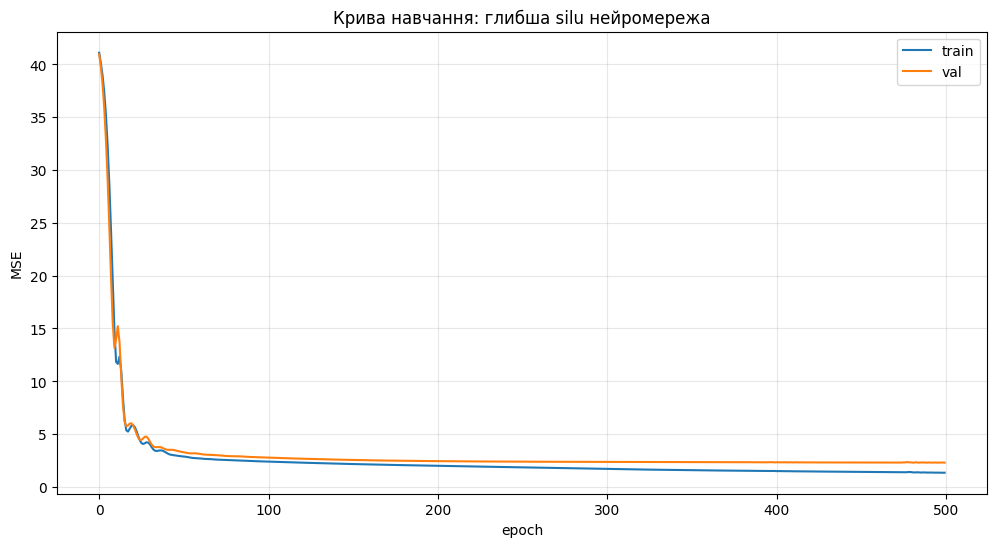

In [92]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(deep_silu_slow_train_losses, label="train")
plt.plot(deep_silu_slow_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: глибша silu нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [88]:
# Метрики
deep_silu_slow_nn.eval()

with torch.no_grad():
    y_test_pred_deep_silu_slow_nn = deep_silu_slow_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")
report(y_test, y_test_pred_deep_silu_nn, "Глибша silu нейромережа")
report(y_test, y_test_pred_deep_silu_slow_nn, "Глибша silu slow нейромережа")

Бейзлайн        MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія   MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа     MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа  MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450
Глибша silu нейромережа  MSE=2.4382  RMSE=1.5615  MAE=0.9698  R2=0.8549
Глибша silu slow нейромережа  MSE=2.3685  RMSE=1.5390  MAE=0.9607  R2=0.8590


In [89]:
# 2) Deep SiLU Slow Early Stop
# Три приховані шари з SiLu: n_features → 128 → 64 → 32 → 1

deep_silu_early_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.SiLU(),
    torch.nn.Linear(128, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 32),
    torch.nn.SiLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(deep_silu_early_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in deep_silu_early_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=128, bias=True)
  (1): SiLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): SiLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): SiLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       12929
Кількість параметрів лінійної: 20


In [90]:
import copy
N_EPOCHS = 500

optimizer = torch.optim.Adam(deep_silu_early_nn.parameters(), lr=0.005)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "deep_silu_early_neural_network"))

deep_silu_early_train_losses, deep_silu_early_val_losses = [], []

patience = 30
min_delta = 0.001

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0
best_model_state = None

for epoch in range(N_EPOCHS):
    deep_silu_early_nn.train()
    optimizer.zero_grad()

    y_pred = deep_silu_early_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    deep_silu_early_train_losses.append(loss.item())

    deep_silu_early_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            deep_silu_early_nn(x_val_t),
            y_val_t
        ).item()

    deep_silu_early_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    # перевірка Early Stopping
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0

        # зберігаємо найкращі ваги
        best_model_state = copy.deepcopy(
            deep_silu_early_nn.state_dict()
        )
    else:
        patience_counter += 1

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}"
        )

    # якщо validation loss довго не покращується
    if patience_counter >= patience:
        print(
            f"\nEarly stopping на епосі {epoch}"
            f"\nНайкраща епоха: {best_epoch}"
            f"\nНайкращий val_loss: {best_val_loss:.4f}"
        )
        break

writer.close()

# повертаємо ваги найкращої версії моделі
deep_silu_early_nn.load_state_dict(best_model_state)

epoch    0  train_loss=40.1708  val_loss=40.2584
epoch   10  train_loss=12.4810  val_loss=11.1411
epoch   20  train_loss=5.3382  val_loss=5.7561
epoch   30  train_loss=4.0326  val_loss=4.4297
epoch   40  train_loss=3.1601  val_loss=3.4393
epoch   50  train_loss=2.8087  val_loss=3.2008
epoch   60  train_loss=2.6785  val_loss=3.1041
epoch   70  train_loss=2.5522  val_loss=2.9532
epoch   80  train_loss=2.4759  val_loss=2.8541
epoch   90  train_loss=2.4090  val_loss=2.7885
epoch  100  train_loss=2.3533  val_loss=2.7335
epoch  110  train_loss=2.3005  val_loss=2.6779
epoch  120  train_loss=2.2499  val_loss=2.6288
epoch  130  train_loss=2.2018  val_loss=2.5834
epoch  140  train_loss=2.1568  val_loss=2.5448
epoch  150  train_loss=2.1149  val_loss=2.5136
epoch  160  train_loss=2.0755  val_loss=2.4851
epoch  170  train_loss=2.0379  val_loss=2.4575
epoch  180  train_loss=2.0024  val_loss=2.4305
epoch  190  train_loss=1.9688  val_loss=2.4058
epoch  200  train_loss=1.9372  val_loss=2.3832
epoch  21

<All keys matched successfully>

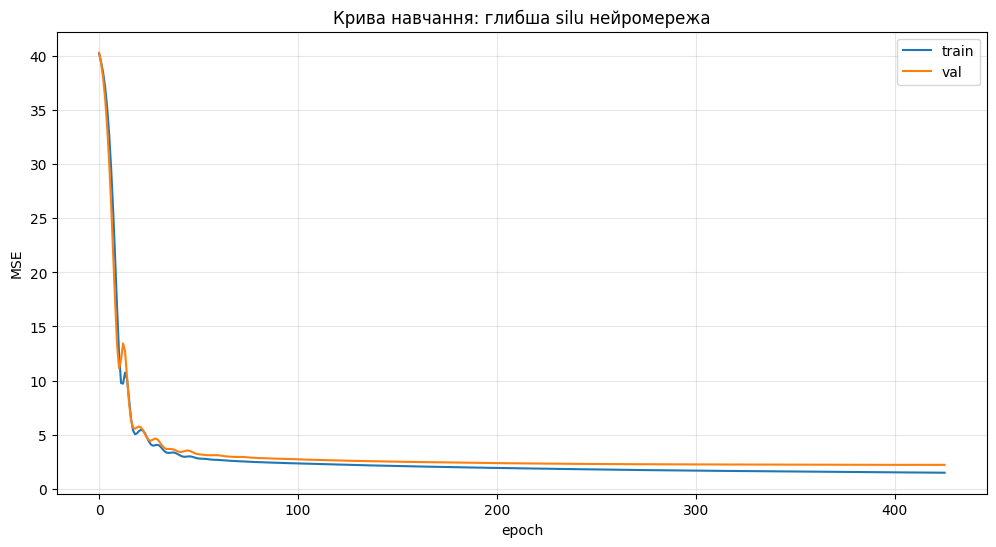

In [91]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(deep_silu_early_train_losses, label="train")
plt.plot(deep_silu_early_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: глибша silu нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [96]:
# Метрики
deep_silu_early_nn.eval()

with torch.no_grad():
    y_test_pred_deep_silu_early_nn = deep_silu_early_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")
report(y_test, y_test_pred_deep_silu_nn, "Глибша silu нейромережа")
report(y_test, y_test_pred_deep_silu_slow_nn, "Глибша silu slow нейромережа")
report(y_test, y_test_pred_deep_silu_early_nn, "Глибша silu slow нейромережа авто-зупинка")


Бейзлайн        MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія   MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа     MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа  MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450
Глибша silu нейромережа  MSE=2.4382  RMSE=1.5615  MAE=0.9698  R2=0.8549
Глибша silu slow нейромережа  MSE=2.3685  RMSE=1.5390  MAE=0.9607  R2=0.8590
Глибша silu slow нейромережа авто-зупинка  MSE=2.3424  RMSE=1.5305  MAE=0.9824  R2=0.8606


In [101]:
# 3) Deep SiLU Slowest Early Stop
# Три приховані шари з SiLu: n_features → 128 → 64 → 32 → 1

deep_silu_slowest_early_nn = torch.nn.Sequential(
    torch.nn.Linear(n_features, 128),
    torch.nn.SiLU(),
    torch.nn.Linear(128, 64),
    torch.nn.SiLU(),
    torch.nn.Linear(64, 32),
    torch.nn.SiLU(),
    torch.nn.Linear(32, 1),
).to(device)

print(deep_silu_slowest_early_nn)
print("Кількість параметрів NN:      ", sum(p.numel() for p in deep_silu_slowest_early_nn.parameters()))
print("Кількість параметрів лінійної:", sum(p.numel() for p in linear_model.parameters()))

Sequential(
  (0): Linear(in_features=19, out_features=128, bias=True)
  (1): SiLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): SiLU()
  (4): Linear(in_features=64, out_features=32, bias=True)
  (5): SiLU()
  (6): Linear(in_features=32, out_features=1, bias=True)
)
Кількість параметрів NN:       12929
Кількість параметрів лінійної: 20


In [102]:
N_EPOCHS = 10000

optimizer = torch.optim.Adam(deep_silu_slowest_early_nn.parameters(), lr=0.0001)
loss_fn = torch.nn.MSELoss()
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "deep_silu_slowest_early_neural_network"))

deep_silu_slowest_train_losses, deep_silu_slowest_val_losses = [], []

patience = 30
min_delta = 0.001

best_val_loss = float("inf")
best_epoch = 0
patience_counter = 0
best_model_state = None

for epoch in range(N_EPOCHS):
    deep_silu_slowest_early_nn.train()
    optimizer.zero_grad()

    y_pred = deep_silu_slowest_early_nn(x_train_t)
    loss = loss_fn(y_pred, y_train_t)

    loss.backward()
    optimizer.step()

    deep_silu_slowest_train_losses.append(loss.item())

    deep_silu_slowest_early_nn.eval()
    with torch.no_grad():
        val_loss = loss_fn(
            deep_silu_slowest_early_nn(x_val_t),
            y_val_t
        ).item()

    deep_silu_slowest_val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    # перевірка Early Stopping
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_epoch = epoch
        patience_counter = 0

        # зберігаємо найкращі ваги
        best_model_state = copy.deepcopy(
            deep_silu_slowest_early_nn.state_dict()
        )
    else:
        patience_counter += 1

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(
            f"epoch {epoch:4d}  "
            f"train_loss={loss.item():.4f}  "
            f"val_loss={val_loss:.4f}"
        )

    # якщо validation loss довго не покращується
    if patience_counter >= patience:
        print(
            f"\nEarly stopping на епосі {epoch}"
            f"\nНайкраща епоха: {best_epoch}"
            f"\nНайкращий val_loss: {best_val_loss:.4f}"
        )
        break

writer.close()

# повертаємо ваги найкращої версії моделі
deep_silu_slowest_early_nn.load_state_dict(best_model_state)

epoch    0  train_loss=40.7999  val_loss=41.6927
epoch   10  train_loss=40.6010  val_loss=41.4853
epoch   20  train_loss=40.3982  val_loss=41.2728
epoch   30  train_loss=40.1827  val_loss=41.0460
epoch   40  train_loss=39.9452  val_loss=40.7949
epoch   50  train_loss=39.6756  val_loss=40.5090
epoch   60  train_loss=39.3636  val_loss=40.1773
epoch   70  train_loss=38.9976  val_loss=39.7879
epoch   80  train_loss=38.5648  val_loss=39.3274
epoch   90  train_loss=38.0510  val_loss=38.7812
epoch  100  train_loss=37.4406  val_loss=38.1331
epoch  110  train_loss=36.7162  val_loss=37.3654
epoch  120  train_loss=35.8601  val_loss=36.4600
epoch  130  train_loss=34.8544  val_loss=35.3994
epoch  140  train_loss=33.6833  val_loss=34.1685
epoch  150  train_loss=32.3349  val_loss=32.7574
epoch  160  train_loss=30.8039  val_loss=31.1638
epoch  170  train_loss=29.0959  val_loss=29.3977
epoch  180  train_loss=27.2300  val_loss=27.4838
epoch  190  train_loss=25.2419  val_loss=25.4641
epoch  200  train_lo

<All keys matched successfully>

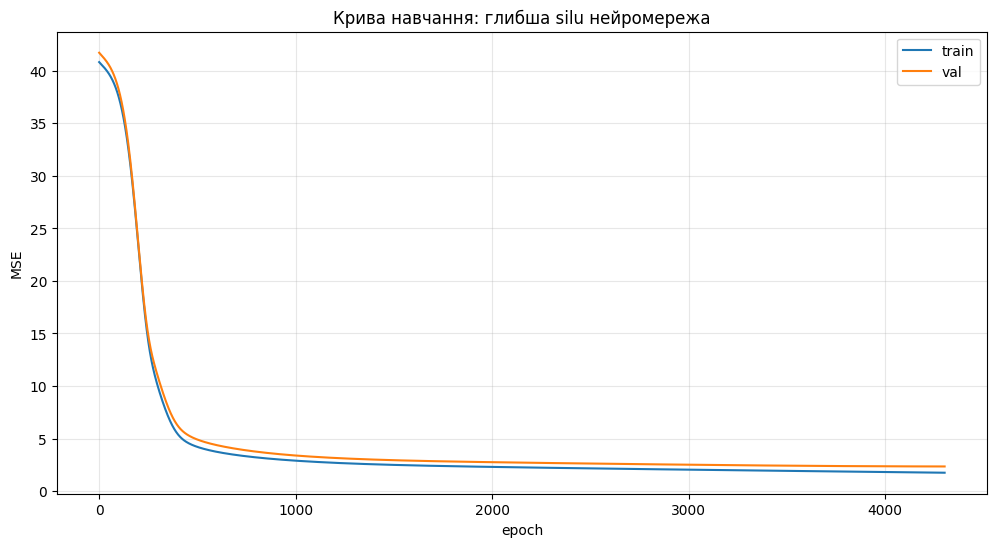

In [103]:
# Крива навчання
plt.figure(figsize=(12, 6))
plt.plot(deep_silu_slowest_train_losses, label="train")
plt.plot(deep_silu_slowest_val_losses, label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("Крива навчання: глибша silu нейромережа")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [109]:
# Метрики
deep_silu_slowest_early_nn.eval()

with torch.no_grad():
    y_test_pred_deep_silu_slowest_nn = deep_silu_slowest_early_nn(x_test_t).cpu().numpy().flatten()

report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")
report(y_test, y_test_pred_deep_silu_nn, "Глибша silu нейромережа")
report(y_test, y_test_pred_deep_silu_slow_nn, "Глибша silu slow нейромережа")
report(y_test, y_test_pred_deep_silu_early_nn, "Глибша silu slow нейромережа авто-зупинка")
report(y_test, y_test_pred_deep_silu_slowest_nn, "Глибша silu slowest нейромережа авто-зупинка")

Бейзлайн                                       MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія                                  MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа                                    MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа                             MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450
Глибша silu нейромережа                        MSE=2.4382  RMSE=1.5615  MAE=0.9698  R2=0.8549
Глибша silu slow нейромережа                   MSE=2.3685  RMSE=1.5390  MAE=0.9607  R2=0.8590
Глибша silu slow нейромережа авто-зупинка      MSE=2.3424  RMSE=1.5305  MAE=0.9824  R2=0.8606
Глибша silu slowest нейромережа авто-зупинка   MSE=2.4954  RMSE=1.5797  MAE=1.0273  R2=0.8515


Зменшення learning rate до `0.0001` і збільшення максимальної кількості епох до `10 000` не дало покращення якості моделі. Early Stopping зупинив навчання приблизно на 4300-й епосі, але отримані метрики виявилися гіршими, ніж для моделі з `lr=0.005`. Це показує, що надто малий learning rate лише значно уповільнює навчання і не гарантує кращого результату.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [110]:
%load_ext tensorboard
%tensorboard --logdir $RUNS_DIR

<IPython.core.display.Javascript object>

In [113]:
report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")
report(y_test, y_test_pred_nn, "Нейромережа")
report(y_test, y_test_pred_deep_nn, "Глибша нейромережа")
report(y_test, y_test_pred_deep_silu_nn, "Глибша silu нейромережа")
report(y_test, y_test_pred_deep_silu_slow_nn, "Глибша silu slow нейромережа")
report(y_test, y_test_pred_deep_silu_early_nn, "Глибша silu slow нейромережа авто-зупинка")
report(y_test, y_test_pred_deep_silu_slowest_nn, "Глибша silu slowest нейромережа авто-зупинка")

Бейзлайн                                       MSE=16.8169  RMSE=4.1008  MAE=2.4264  R2=-0.0009
Лін. регресія                                  MSE=5.2465  RMSE=2.2905  MAE=1.3451  R2=0.6877
Нейромережа                                    MSE=2.6216  RMSE=1.6191  MAE=1.0189  R2=0.8440
Глибша нейромережа                             MSE=2.6036  RMSE=1.6136  MAE=1.0253  R2=0.8450
Глибша silu нейромережа                        MSE=2.4382  RMSE=1.5615  MAE=0.9698  R2=0.8549
Глибша silu slow нейромережа                   MSE=2.3685  RMSE=1.5390  MAE=0.9607  R2=0.8590
Глибша silu slow нейромережа авто-зупинка      MSE=2.3424  RMSE=1.5305  MAE=0.9824  R2=0.8606
Глибша silu slowest нейромережа авто-зупинка   MSE=2.4954  RMSE=1.5797  MAE=1.0273  R2=0.8515


## Яка модель перемогла і на скільки суттєво

Deep Silu lr=0,05 Early Stop (шось на кшталт xiaomi redmi note 10 pro) з RMSE у `1.5305` одиниць (`1 = 100.000$`).  
Різниця з лінійною: `$229.050 - $153.050 ~ $76.000`  
Тобто нейромережа зменшила типову RMSE-помилку приблизно на $76 тис.  

## Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?

Нейромережа суттєво перевершила лінійну регресію. Найкраща модель зменшила RMSE приблизно з `$229 тис. до $153 тис.`, тобто приблизно на `$76 тис.`, а коефіцієнт детермінації `R²` зріс з `0.688 до 0.861`. Отже, використання нелінійної моделі для цього датасету виправдало себе  

## Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

Найбільший ефект дав сам перехід від лінійної регресії до нейромережі.  
Просте збільшення глибини мережі майже не покращило результат суттєво. Серед подальших змін найбільш корисними виявилися використання функції активації SiLU, зменшення learning rate до 0.005 та застосування Early Stopping. Надмірне зменшення learning rate до 0.0001, навпаки, погіршило результат

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [114]:
!pip install -q gradio
import gradio as gr

In [120]:
models = {
    "Лінійна регресія": linear_model,
    "Базова NN": housing_nn,
    "Deep ReLU": deep_nn,
    "Deep SiLU": deep_silu_nn,
    "Deep SiLU lr=0.005": deep_silu_slow_nn,
    "Deep SiLU + EarlyStop": deep_silu_early_nn,
    "Deep SiLU lr=0.0001 + EarlyStop": deep_silu_slowest_early_nn
}

In [121]:
def build_input(
    bedrooms,
    bathrooms,
    sqft_living,
    sqft_lot,
    floors,
    waterfront,
    view,
    condition,
    grade,
    yr_built,
    zipcode,
):
    # беремо типовий будинок з train як основу
    row = train_df.mean(numeric_only=True).to_dict()

    # заміняємо ключові поля значеннями користувача
    row["bedrooms"] = bedrooms
    row["bathrooms"] = bathrooms
    row["sqft_living"] = sqft_living
    row["sqft_lot"] = sqft_lot
    row["floors"] = floors
    row["waterfront"] = waterfront
    row["view"] = view
    row["condition"] = condition
    row["grade"] = grade
    row["yr_built"] = yr_built
    row["zipcode"] = zipcode

    # DataFrame з одним будинком
    df = pd.DataFrame([row])

    # ті самі feature engineering, що й при навчанні
    df = transform_features(df)

    return df

def predict_all(*feature_values):
    df = build_input(*feature_values)

    x = scaler.transform(df[feature_cols])
    x_t = torch.tensor(x, dtype=torch.float32).to(device)

    preds = {}

    for name, model in models.items():
        model.eval()

        with torch.no_grad():
            # модель прогнозує ціну в одиницях по $100 000
            pred = model(x_t).item() * PRICE_SCALE

        preds[name] = pred

    return preds


def predict_selected(selected_model, *feature_values):
    return predict_all(*feature_values)[selected_model]

def plot_comparison(*feature_values):
    preds = predict_all(*feature_values)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(preds.keys(), preds.values())
    ax.set_ylabel("Прогнозована ціна, $")
    ax.set_title("Порівняння моделей")

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    return fig

def run_prediction(selected_model, *feature_values):
    prediction = predict_selected(
        selected_model,
        *feature_values
    )

    plot = plot_comparison(*feature_values)

    return prediction, plot

In [122]:
with gr.Blocks(title="King County Housing — прогноз ціни") as demo:

    gr.Markdown(
        "## Прогноз вартості будинку\n"
        "Вкажіть основні характеристики будинку та оберіть модель."
    )

    with gr.Row():

        with gr.Column():

            bedrooms = gr.Slider(
                minimum=1,
                maximum=10,
                value=3,
                step=1,
                label="Кількість спалень",
            )

            bathrooms = gr.Slider(
                minimum=1,
                maximum=6,
                value=2,
                step=0.25,
                label="Кількість ванних кімнат",
            )

            sqft_living = gr.Slider(
                minimum=500,
                maximum=7000,
                value=2000,
                step=50,
                label="Житлова площа (sqft)",
            )

            sqft_lot = gr.Slider(
                minimum=500,
                maximum=50000,
                value=7500,
                step=100,
                label="Площа ділянки (sqft)",
            )

            floors = gr.Slider(
                minimum=1,
                maximum=3.5,
                value=1,
                step=0.5,
                label="Кількість поверхів",
            )

            waterfront = gr.Radio(
                choices=[0, 1],
                value=0,
                label="На березі водойми",
            )

            view = gr.Slider(
                minimum=0,
                maximum=4,
                value=0,
                step=1,
                label="Оцінка виду",
            )

            condition = gr.Slider(
                minimum=1,
                maximum=5,
                value=3,
                step=1,
                label="Стан будинку",
            )

            grade = gr.Slider(
                minimum=1,
                maximum=13,
                value=7,
                step=1,
                label="Клас будинку",
            )

            yr_built = gr.Slider(
                minimum=1900,
                maximum=2015,
                value=1990,
                step=1,
                label="Рік побудови",
            )

            zipcode = gr.Number(
                value=98103,
                label="ZIP code",
            )

            model_choice = gr.Dropdown(
                choices=list(models.keys()),
                value="Deep SiLU + EarlyStop",
                label="Модель",
            )

            submit_btn = gr.Button(
                "Порахувати прогноз",
                variant="primary",
            )

        with gr.Column():

            prediction_output = gr.Number(
                label="Прогнозована ціна, $"
            )

            comparison_plot = gr.Plot(
                label="Порівняння моделей"
            )

    inputs = [
        bedrooms,
        bathrooms,
        sqft_living,
        sqft_lot,
        floors,
        waterfront,
        view,
        condition,
        grade,
        yr_built,
        zipcode,
    ]

    submit_btn.click(
        fn=run_prediction,
        inputs=[model_choice] + inputs,
        outputs=[
            prediction_output,
            comparison_plot,
        ],
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b97db3bcd64c8c6158.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://b97db3bcd64c8c6158.gradio.live


In [123]:
# Зведена таблиця результатів усіх моделей
predictions = {
    "Лінійна регресія": y_test_pred,
    "Базова NN": y_test_pred_nn,
    "Deep ReLU": y_test_pred_deep_nn,
    "Deep SiLU": y_test_pred_deep_silu_nn,
    "Deep SiLU lr=0.005": y_test_pred_deep_silu_slow_nn,
    "Deep SiLU + EarlyStop": y_test_pred_deep_silu_early_nn,
    "Deep SiLU lr=0.0001 + EarlyStop": y_test_pred_deep_silu_slowest_nn,
}

results = []

for name, y_pred in predictions.items():
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2,
    })

results_df = pd.DataFrame(results)

results_df

,model,MSE,RMSE,MAE,R2
0,Лінійна регресія,5.25,2.29,1.35,0.69
1,Базова NN,2.62,1.62,1.02,0.84
2,Deep ReLU,2.60,1.61,1.03,0.85
3,Deep SiLU,2.44,1.56,0.97,0.85
4,Deep SiLU lr=0.005,2.37,1.54,0.96,0.86
5,Deep SiLU + EarlyStop,2.34,1.53,0.98,0.86
6,Deep SiLU lr=0.0001 + EarlyStop,2.50,1.58,1.03,0.85


In [124]:
results_path = os.path.join(ARTIFACT_DIR, "results.csv")

results_df.to_csv(
    results_path,
    index=False,
    encoding="utf-8-sig"
)

print("Збережено:", results_path)

Збережено: /content/drive/MyDrive/ai_systems/lecture3/results.csv


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```